# The worst case: every single line an interloper

The worst case of line interlopers: **no single-line galaxy keeps its redshift**. Each single line is taken for another
line, for one that gives it a redshift inside the range wherever there is one. The catalog then holds the multi-line
galaxies of the range and every single line of another redshift that some line puts inside it, while the single-line
galaxies of the range leave it. No probability is chosen and no random number is drawn: it is the most interlopers an
identification can make, and the same galaxies always give the same catalog.

1. **`base.make_proposal(z_range, line="all", thresholds)`**, as in notebooks 01 and 02.
   `proposal.worst_case_summary()` gives the catalog the worst case makes, from the counts of the proposal: its
   interlopers per pair (the true line and the line it is taken for), and every other way a single line could get a
   redshift inside the range, with why the worst case leaves it out.
2. **`proposal.make_catalog("worst_case", out_dir)`** makes it (`romanmock.confusion.WorstCaseConfusion`) and prints
   the numbers expected and made.

**The lines a single line is taken for** are those that single-line galaxies inside the range show:
`proposal.worst_case_lines()`, the same lines as the potential interlopers of the proposal (`proposal.assignable`): the
single line of at least 100 galaxies and 0.1 % of the single-line galaxies inside the range. By wavelength alone a
single Hα line could also pass for Hβ, [O III] λ4959 or [S III] λ6312, but no galaxy of these ranges has one of those as
its only line, so no identification would choose them. `{"type": "worst_case", "taken_for": [...]}` chooses the lines
instead.

**A wrong redshift inside the range.** A single line of the range taken for another line stays inside it only if the
two lines are closer in wavelength than the range is wide in 1 + z: (1 + 1.2) / (1 + 1.0) = 1.10 and
(1 + 2.0) / (1 + 1.6) = 1.15. Hα and [O III] λ5007 are 1.31 apart, so an Hα line of the range taken for [O III] always
leaves it. `proposal.misidentifications()` lists the pairs that could keep a single line inside.

The thresholds are those of notebooks 01 and 02 (flux limits 1.5 and 0.6 × 10⁻¹⁶ erg s⁻¹ cm⁻²), with the oxygen lines
rescaled (`RESCALING`, first cell). The notebook reads the base catalog four times. Run it on a CPU node, from the
package directory: `sbatch scripts/run_notebook.sh notebooks/06_worst_case.ipynb` (about 2 minutes). The catalogs go
to `$PSCRATCH/RomanMocks/examples/`.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")      # romanmock imports diffsky, which imports JAX; keep it off the GPU

import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from romanmock import BaseCatalog, LineFactors, plotting
from romanmock.plotting import OUTCOME_COLORS, TEXT_PRIMARY, feature_color, feature_label

plotting.use_style()
BASE = "/global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_261013_10_14_2026/base"
OUT = Path(os.environ["PSCRATCH"]) / "RomanMocks" / "examples"      # scratch: purged after 8 weeks without access
N_WORKERS = 64 if "SLURM_JOB_ID" in os.environ else None           # a whole CPU node; None: what a login node allows
base = BaseCatalog(BASE)
print(base)

# The rescaling of the oxygen lines (introduction of notebook 01): [O III] gets a scatter of 0.19 dex, and [O II] is
# brightened by 0.25 dex with a scatter of 0.11 dex. One deviate per galaxy; the other lines keep their raw fluxes.
RESCALING = LineFactors(log_offsets={"OII_3727": 0.25}, scatter={"OIII_5007": 0.19, "OIII_4959": 0.19, "OII_3727": 0.11})
print(RESCALING.describe(base.line_set))
THRESHOLDS = {"flux_limit": 1.5e-16, "secondary_flux_limit": 6e-17}      # those of notebooks 01 and 02

<BaseCatalog /global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_261013_10_14_2026/base: 403,068,868 galaxies in 67 slices, 0.00 < z < 4.00; flux limit 1.00e-18 erg/s/cm2 in 10000-19300 A; lines ['Ha', 'Hb', 'OIII_5007', 'OIII_4959', 'OII_3727', 'SIII_9532', 'SIII_9069', 'OIII_4363', 'SIII_6312', 'PaA']>
line_factors rescaling: OIII_5007 x1.000 ±0.19 dex, OIII_4959 x1.000 ±0.19 dex, OII_3727 x1.778 ±0.11 dex


## 1.0 < z < 1.2

### Step 1: the proposal and its worst case

The proposal is that of every galaxy in notebook 01 (`verbose=False` leaves out its summary, shown there).
`repr(proposal)` lists its potential interlopers; `worst_case_summary()` gives the worst case.

In [2]:
proposal = base.make_proposal((1.0, 1.2), line="all", **THRESHOLDS, rescaling=RESCALING, n_workers=N_WORKERS, verbose=False)
print(repr(proposal), "\n")
print("lines a single line is taken for:", proposal.worst_case_lines(), "\n")
print(proposal.worst_case_summary())

<Proposal: every galaxy at 1.0–1.2, 13,599,636 galaxies; potential interlopers: SIII_9532 as Ha, Ha as OIII_5007, SIII_9532 as OIII_5007> 

lines a single line is taken for: ['Ha', 'OIII_5007'] 

━━ Worst case · every galaxy at 1.0 ≤ z ≤ 1.2: every single line an interloper ━━━━━━━━━━━━━━━━━━━━━
  identification   every single line taken for another line, for one of Ha, OIII_5007 that puts it
                   inside the range wherever there is one
  sample           13,599,636 detected galaxies inside the range, 375,059 of them single-line
  catalog          14,096,887 galaxies expected: 13,224,577 multi-line + 872,310 interlopers
                   (6.19 %)

  line       taken for  true z       interlopers  from inside¹  share²
  ─────────  ─────────  ───────────  ───────────  ────────────  ──────
  Ha         OIII_5007  0.526–0.678      721,584             0  5.12 %
  SIII_9532  OIII_5007  0.051–0.156      119,718             0  0.85 %
  SIII_9532  Ha         0.377–0.515       28,2

For every galaxy at 1.0 < z < 1.2:

* **The single lines of the range** are 375,059 galaxies, 2.76 % of the detected ones: Hα in 369,953 and [O III] in
  5,106 (1.4 % of the single-line galaxies). A single line is therefore taken for Hα or for [O III].
* **The worst case holds 14.10 M galaxies**, the 13.22 M multi-line galaxies of the range and 872,310 interlopers
  (6.19 %):
  * Hα at 0.53–0.68 taken for [O III]: 721,584, 5.1 % of the catalog. At 10 000–11 000 Å a single line is Hα at
    z ≈ 0.6 far more often than [O III] inside the range, so this is the largest pair although [O III] is rarely
    single here;
  * [S III] λ9532 at 0.05–0.16 taken for [O III]: 119,718 (0.85 %), the only line of these galaxies in the bandpass;
  * [S III] λ9532 at 0.38–0.52 taken for Hα: 28,226 (0.20 %), and [O III] at 1.62–1.88 taken for Hα: 2,782 (0.02 %).
* **Every single line of the range leaves it**: Hα taken for [O III] goes to z = 1.62–1.88, and [O III] taken for Hα
  to 0.53–0.68.
* **The proposal lists the same three pairs as its potential interlopers** (`repr`, and its summary in notebook 01):
  at most 6.0 % of a catalog that keeps its sample, and 6.19 % here, where the single lines of the range are lost.

### Every way a single line can land in the range

`proposal.misidentifications()` has one row per pair, for every line in the bandpass that a single line could be taken
for, not only those of the worst case. Below are the pairs with at least 1,000 single lines and every pair that keeps
a single line of the range inside it ("from inside"). "Its own" is the number of galaxies inside the range whose single
line is the taken-for line: where it is 0, no identification would choose that line, and the worst case leaves the
pair out.

In [3]:
def show_misidentifications(proposal, min_n=1000):
    """The rows of proposal.misidentifications() with at least min_n single lines or any from inside the range."""
    lo, hi = proposal.z_range
    print(f"{'line':<11s}{'taken for':<11s}{'true z':<14s}{'single lines':>13s}{'from inside':>13s}{'its own':>10s}"
          f"{'worst case':>12s}")
    for r in proposal.misidentifications():
        if r["n"] >= min_n or r["n_inside"]:
            z0, z1 = max(r["z_true"][0], 0.0), r["z_true"][1]
            print(f"{r['line']:<11s}{r['as']:<11s}{z0:.3f}–{z1:<8.3f}{r['n']:>13,}{r['n_inside']:>13,}"
                  f"{r['single_inside']:>10,}{'yes' if r['worst_case'] else '':>12s}")
    print(f"\na single line of the range stays inside it only when taken for a line less than "
          f"(1 + {hi}) / (1 + {lo}) = {(1 + hi) / (1 + lo):.3f} times redder or bluer")


show_misidentifications(proposal)

line       taken for  true z         single lines  from inside   its own  worst case
Ha         OIII_5007  0.526–0.678         721,584            0     5,106         yes
Ha         SIII_6312  0.924–1.116         672,956      197,528         0            
Ha         OIII_4959  0.523–0.662         645,549            0         0            
Ha         Hb         0.523–0.630         478,396            0         0            
Ha         SIII_9069  1.764–1.940         225,052            0         0            
SIII_9532  OIII_4959  0.049–0.145         121,414            0         0            
SIII_9532  Hb         0.049–0.122         121,381            0         0            
SIII_9532  OIII_5007  0.051–0.156         119,718            0     5,106         yes
Ha         SIII_9532  1.904–1.940          43,150            0         0            
OIII_5007  SIII_9069  2.622–2.854          40,793            0         0            
SIII_9532  Ha         0.377–0.515          28,226            0   

* **Only lines that no galaxy of the range shows alone could keep a single line inside it with a wrong redshift**: Hα
  taken for [S III] λ6312 (wavelength ratio 1.040; 197,528 single Hα lines of the range), [O III] λ5007 taken for
  λ4959 (1.010; 4,477) or for Hβ (1.030; 3,227). Their "its own" is 0, so the worst case leaves them out.
* **Hα taken for [O III] never stays inside**: the lines are 1.311 apart, more than the 1.10 of the range.
* The same lines would bring many single lines from outside: Hα of 0.52–0.66 taken for [O III] λ4959 (645,549) or
  for Hβ (478,396).

### Step 2: the catalog

`make_catalog("worst_case", out_dir)` prints the worst case again, the summary of the catalog and its line report, and
then the numbers expected and made.

In [4]:
cat = proposal.make_catalog("worst_case", OUT / "all_z1p0_1p2_worst_case", n_workers=N_WORKERS)

━━ Worst case · every galaxy at 1.0 ≤ z ≤ 1.2: every single line an interloper ━━━━━━━━━━━━━━━━━━━━━
  identification   every single line taken for another line, for one of Ha, OIII_5007 that puts it
                   inside the range wherever there is one
  sample           13,599,636 detected galaxies inside the range, 375,059 of them single-line
  catalog          14,096,887 galaxies expected: 13,224,577 multi-line + 872,310 interlopers
                   (6.19 %)

  line       taken for  true z       interlopers  from inside¹  share²
  ─────────  ─────────  ───────────  ───────────  ────────────  ──────
  Ha         OIII_5007  0.526–0.678      721,584             0  5.12 %
  SIII_9532  OIII_5007  0.051–0.156      119,718             0  0.85 %
  SIII_9532  Ha         0.377–0.515       28,226             0  0.20 %
  OIII_5007  Ha         1.622–1.884        2,782             0  0.02 %
  ¹ true redshift inside the range: taken for that line they stay inside, with a wrong redshift
  ² 

[romanmock] catalog: scanning 67 slices with 64 worker(s) …

 done in 31 s



━━ Catalog · every galaxy · 1.0 ≤ z_assigned ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds       F > 1.50e-16 (other lines > 6.00e-17)
  line fluxes      rescaled (line_factors); [O III] doublet per_galaxy
  identification   worst case: every single line taken for another line (Ha, OIII_5007), one that
                   puts it inside 1–1.2 wherever there is one
  sky area         2578.31 deg² (estimated from the sky patches of the mock)
  base catalog     91,617,494 of its 403,068,868 galaxies detected
  columns          gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome,
                   line_true, line_assigned, n_det

  galaxies                                       number     share
  ─────────────────────────────────────────  ──────────  ────────
  multi-line                                 13,224,577   93.81 %
  single line taken for another: interloper     872,310    6.19 %
  all                                        14,096,88


── Worst case: expected and made ───────────────────────────────────────────────────────────────────
  line         taken for    expected        made
  ───────────  ─────────  ──────────  ──────────
  Ha           OIII_5007     721,584     721,584
  SIII_9532    OIII_5007     119,718     119,718
  SIII_9532    Ha             28,226      28,226
  OIII_5007    Ha              2,782       2,782
  interlopers                872,310     872,310
  multi-line              13,224,577  13,224,577
  catalog                 14,096,887  14,096,887
  0 single-line galaxies with their true redshift (the worst case keeps none); the expectation
  counts true and assigned redshifts in the proposal's bins of the range, the catalog cuts both ends
  inclusive, so a galaxy exactly on an end can differ



[romanmock] wrote to /pscratch/sd/w/willlake/RomanMocks/examples/all_z1p0_1p2_worst_case/
            all_z1p0_1p2.hdf5, all_z1p0_1p2_summary.json, all_z1p0_1p2_proposal.npz


The catalog holds exactly what the proposal expected: 14,096,887 galaxies, 872,310 interlopers with the same numbers
per pair, and no single-line galaxy with its true redshift.

## 1.6 < z < 2.0

The same for every galaxy at 1.6 < z < 2.0, the proposal of notebook 02.

In [5]:
proposal_2 = base.make_proposal((1.6, 2.0), line="all", **THRESHOLDS, rescaling=RESCALING, n_workers=N_WORKERS, verbose=False)
print(repr(proposal_2), "\n")
print(proposal_2.worst_case_summary(), "\n")
show_misidentifications(proposal_2)

<Proposal: every galaxy at 1.6–2.0, 9,664,858 galaxies; potential interlopers: OIII_5007 as Ha, OII_3727 as Ha, Ha as OIII_5007, OII_3727 as OIII_5007, SIII_9532 as OIII_5007> 

━━ Worst case · every galaxy at 1.6 ≤ z ≤ 2.0: every single line an interloper ━━━━━━━━━━━━━━━━━━━━━
  identification   every single line taken for another line, for one of Ha, OIII_5007 that puts it
                   inside the range wherever there is one
  sample           9,664,858 detected galaxies inside the range, 504,589 of them single-line
  catalog          10,068,845 galaxies expected: 9,160,269 multi-line + 908,576 interlopers (9.02 %)

  line       taken for  true z       interlopers  from inside¹  share²
  ─────────  ─────────  ───────────  ───────────  ────────────  ──────
  Ha         OIII_5007  0.984–1.289      634,770             0  6.30 %
  OII_3727   Ha         3.578–4.176      104,795             0  1.04 %
  OIII_5007  Ha         2.408–2.854       92,477             0  0.92 %
  OII_3727   O

* **The single lines of the range** are 504,589 galaxies (5.22 %): Hα in 464,267 and [O III] in 40,322 (8.0 % of the
  single-line galaxies).
* **The worst case holds 10.07 M galaxies**, the 9.16 M multi-line galaxies and 908,576 interlopers (9.02 %):
  * Hα at 0.98–1.29 taken for [O III]: 634,770 (6.3 %);
  * [O II] at 3.58–4.18 taken for Hα: 104,795 (1.04 %), the only line in the bandpass at those redshifts;
  * [O III] at 2.41–2.85 taken for Hα: 92,477 (0.92 %);
  * [O II] at 2.49–3.03 (40,338) and [S III] λ9532 at 0.37–0.58 (32,223) taken for [O III], and Paα at z < 0.03
    taken for Hα (3,973).
* **Again no single line of the range stays inside it.** The pairs that could keep one are taken for lines no galaxy
  of the range shows alone (ratio below 1.154): Hα taken for [S III] λ6312 (397,456), [O III] λ5007 for λ4959
  (23,149), Hβ (3,424) or [O III] λ4363 (331).

In [6]:
cat_2 = proposal_2.make_catalog("worst_case", OUT / "all_z1p6_2p0_worst_case", n_workers=N_WORKERS)

━━ Worst case · every galaxy at 1.6 ≤ z ≤ 2.0: every single line an interloper ━━━━━━━━━━━━━━━━━━━━━
  identification   every single line taken for another line, for one of Ha, OIII_5007 that puts it
                   inside the range wherever there is one
  sample           9,664,858 detected galaxies inside the range, 504,589 of them single-line
  catalog          10,068,845 galaxies expected: 9,160,269 multi-line + 908,576 interlopers (9.02 %)

  line       taken for  true z       interlopers  from inside¹  share²
  ─────────  ─────────  ───────────  ───────────  ────────────  ──────
  Ha         OIII_5007  0.984–1.289      634,770             0  6.30 %
  OII_3727   Ha         3.578–4.176      104,795             0  1.04 %
  OIII_5007  Ha         2.408–2.854       92,477             0  0.92 %
  OII_3727   OIII_5007  2.492–3.030       40,338             0  0.40 %
  SIII_9532  OIII_5007  0.366–0.576       32,223             0  0.32 %
  PaA        Ha         0.000–0.029        3,973  

[romanmock] catalog: scanning 67 slices with 64 worker(s) …

 done in 26 s



━━ Catalog · every galaxy · 1.6 ≤ z_assigned ≤ 2.0 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds       F > 1.50e-16 (other lines > 6.00e-17)
  line fluxes      rescaled (line_factors); [O III] doublet per_galaxy
  identification   worst case: every single line taken for another line (Ha, OIII_5007), one that
                   puts it inside 1.6–2 wherever there is one
  sky area         2578.31 deg² (estimated from the sky patches of the mock)
  base catalog     91,617,494 of its 403,068,868 galaxies detected
  columns          gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome,
                   line_true, line_assigned, n_det

  galaxies                                       number     share
  ─────────────────────────────────────────  ──────────  ────────
  multi-line                                  9,160,269   90.98 %
  single line taken for another: interloper     908,576    9.02 %
  all                                        10,068,84


── Worst case: expected and made ───────────────────────────────────────────────────────────────────
  line         taken for    expected        made
  ───────────  ─────────  ──────────  ──────────
  Ha           OIII_5007     634,770     634,770
  OII_3727     Ha            104,795     104,795
  OIII_5007    Ha             92,477      92,477
  OII_3727     OIII_5007      40,338      40,338
  SIII_9532    OIII_5007      32,223      32,223
  PaA          Ha              3,973       3,973
  interlopers                908,576     908,576
  multi-line               9,160,269   9,160,269
  catalog                 10,068,845  10,068,845
  0 single-line galaxies with their true redshift (the worst case keeps none); the expectation
  counts true and assigned redshifts in the proposal's bins of the range, the catalog cuts both ends
  inclusive, so a galaxy exactly on an end can differ



[romanmock] wrote to /pscratch/sd/w/willlake/RomanMocks/examples/all_z1p6_2p0_worst_case/
            all_z1p6_2p0.hdf5, all_z1p6_2p0_summary.json, all_z1p6_2p0_proposal.npz


Again the catalog holds exactly the numbers expected: 10,068,845 galaxies, of them 908,576 interlopers.

## What is in the catalogs

`cat.components()` counts the multi-line galaxies, the interlopers and each kind of interloper (notebook 01 explains
`id_outcome`, `line_true` and `line_assigned`); there are no single-line galaxies with a correct redshift. The figure
draws their dN/dz against the assigned redshift, a kind of interloper in the colour of its true line and one line style
per line it is taken for. The table below it gives the share of interlopers in slices of assigned redshift.

(a) worst case at 1.0 < z < 1.2: 14,096,887 galaxies
  all                       14,096,887   100.000 %


  multi_line                13,224,577    93.812 %


  single_correct                     0     0.000 %
  galaxies                  13,224,577    93.812 %
  interlopers                  872,310     6.188 %
  Ha_as_OIII_5007              721,584     5.119 %
  SIII_9532_as_OIII_5007       119,718     0.849 %
  SIII_9532_as_Ha               28,226     0.200 %
  OIII_5007_as_Ha                2,782     0.020 %


(b) worst case at 1.6 < z < 2.0: 10,068,845 galaxies
  all                       10,068,845   100.000 %
  multi_line                 9,160,269    90.976 %


  single_correct                     0     0.000 %
  galaxies                   9,160,269    90.976 %
  interlopers                  908,576     9.024 %
  Ha_as_OIII_5007              634,770     6.304 %
  OII_3727_as_Ha               104,795     1.041 %
  OIII_5007_as_Ha               92,477     0.918 %
  OII_3727_as_OIII_5007         40,338     0.401 %
  SIII_9532_as_OIII_5007        32,223     0.320 %
  PaA_as_Ha                      3,973     0.039 %


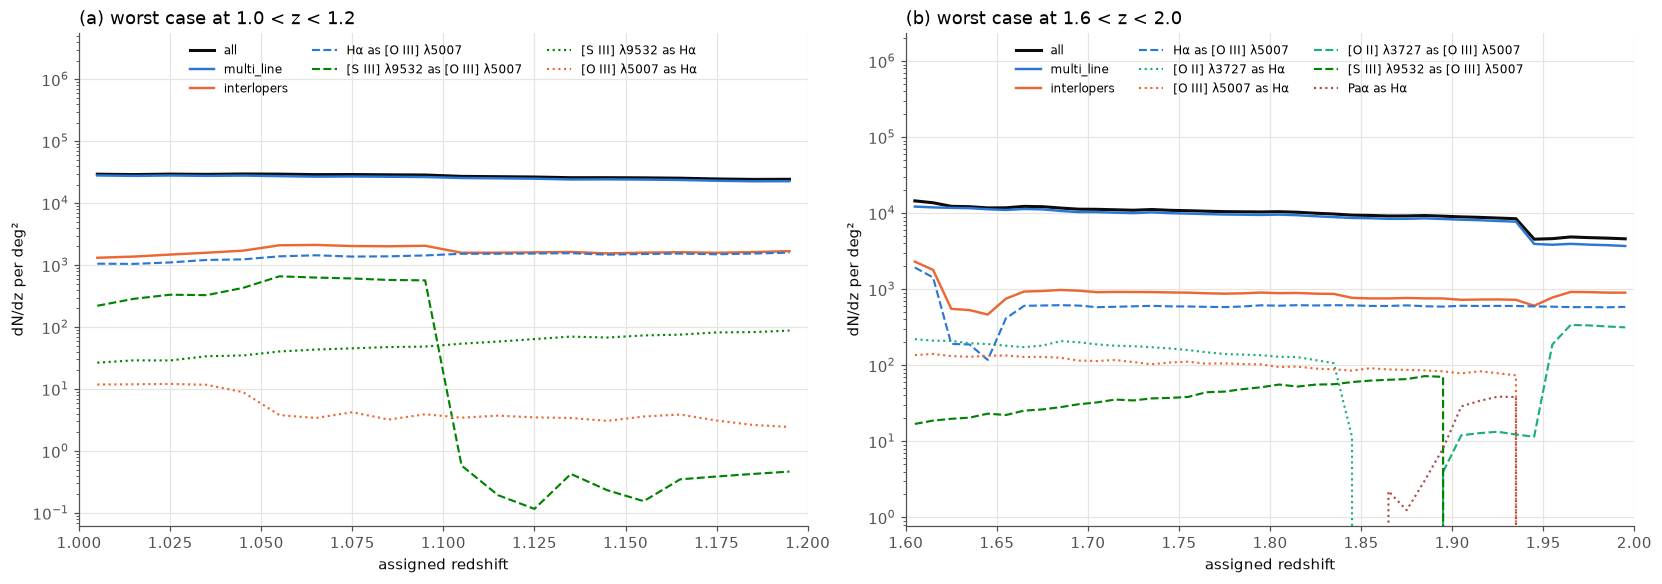

interlopers per slice of assigned z: 1.00–1.05 5.1 %, 1.05–1.10 7.1 %, 1.10–1.15 6.0 %, 1.15–1.20 6.5 %
interlopers per slice of assigned z: 1.60–1.65 8.8 %, 1.65–1.70 7.7 %, 1.70–1.75 8.3 %, 1.75–1.80 8.4 %, 1.80–1.85 8.6 %, 1.85–1.90 8.2 %, 1.90–1.95 8.9 %, 1.95–2.00 18.7 %


In [7]:
COLORS = {"all": TEXT_PRIMARY, "multi_line": OUTCOME_COLORS["MULTI_LINE"], "single_correct": OUTCOME_COLORS["SINGLE_CORRECT"],
          "interlopers": OUTCOME_COLORS["SINGLE_MISID"]}


def show_components(cat, name, ax, edges, min_count=100):
    """Print the components of a catalog and draw dN/dz of each against the assigned redshift. A kind of interloper
    has the colour of its true line and one line style per line it is taken for; those with fewer than min_count
    galaxies are listed only."""
    comp = cat.components()
    zc = 0.5 * (edges[1:] + edges[:-1])
    styles = {}
    print(f"{name}: {len(cat):,} galaxies")
    for which, n in comp.items():
        print(f"  {which:<24s}{n:>12,}{100 * n / comp['all']:>10.3f} %")
        if which == "galaxies" or n < min_count:
            continue
        if which in COLORS:
            ax.plot(zc, cat.subset(which).dndz(edges), color=COLORS[which], lw=2.0 if which == "all" else 1.6, label=which)
        else:
            true, taken = which.split("_as_")
            ls = styles.setdefault(taken, ("--", ":", "-.")[len(styles) % 3])
            ax.plot(zc, cat.subset(which).dndz(edges), color=feature_color(true), ls=ls, lw=1.4,
                    label=f"{feature_label(true)} as {feature_label(taken)}")
    ax.set_yscale("log")
    low, high = ax.get_ylim()
    ax.set_ylim(low, high * 100)                 # room above the curves for the legend
    ax.set_xlim(edges[0], edges[-1])
    ax.set_xlabel("assigned redshift")
    ax.set_ylabel("dN/dz per deg²")
    ax.set_title(name, loc="left")
    ax.legend(fontsize=8, ncol=3, loc="upper center")


def interloper_share(cat, edges):
    """The share of interlopers in each slice of assigned redshift."""
    z = np.asarray(cat["redshift_assigned"])
    wrong = np.asarray(cat["id_outcome"]) == 3
    return np.histogram(z[wrong], edges)[0] / np.histogram(z, edges)[0]


fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), constrained_layout=True)
show_components(cat, "(a) worst case at 1.0 < z < 1.2", axes[0], np.linspace(1.0, 1.2, 21))
show_components(cat_2, "(b) worst case at 1.6 < z < 2.0", axes[1], np.linspace(1.6, 2.0, 41))
plt.show()
for c, edges in ((cat, np.linspace(1.0, 1.2, 5)), (cat_2, np.linspace(1.6, 2.0, 9))):
    print("interlopers per slice of assigned z:",
          ", ".join(f"{a:.2f}–{b:.2f} {100 * s:.1f} %" for a, b, s in zip(edges[:-1], edges[1:], interloper_share(c, edges))))

* **(a) At 1.0–1.2** the interlopers are 5–7 % of the catalog at every redshift, nearly all Hα of z ≈ 0.6 taken for
  [O III].
* **(b) At 1.6–2.0** they are 7–9 % up to z = 1.94, mostly Hα of z ≈ 1.1 taken for [O III], and 19 % above it: Hα has
  left the grism, so the catalog holds half as many galaxies there, while [O II] of z ≈ 3 still passes for [O III].

### Where the interlopers come from

The true redshift of each kind of interloper (`redshift_rsd`), in the colour of its true line and the line style of the
line it is taken for. The grey band is the range of the catalog.

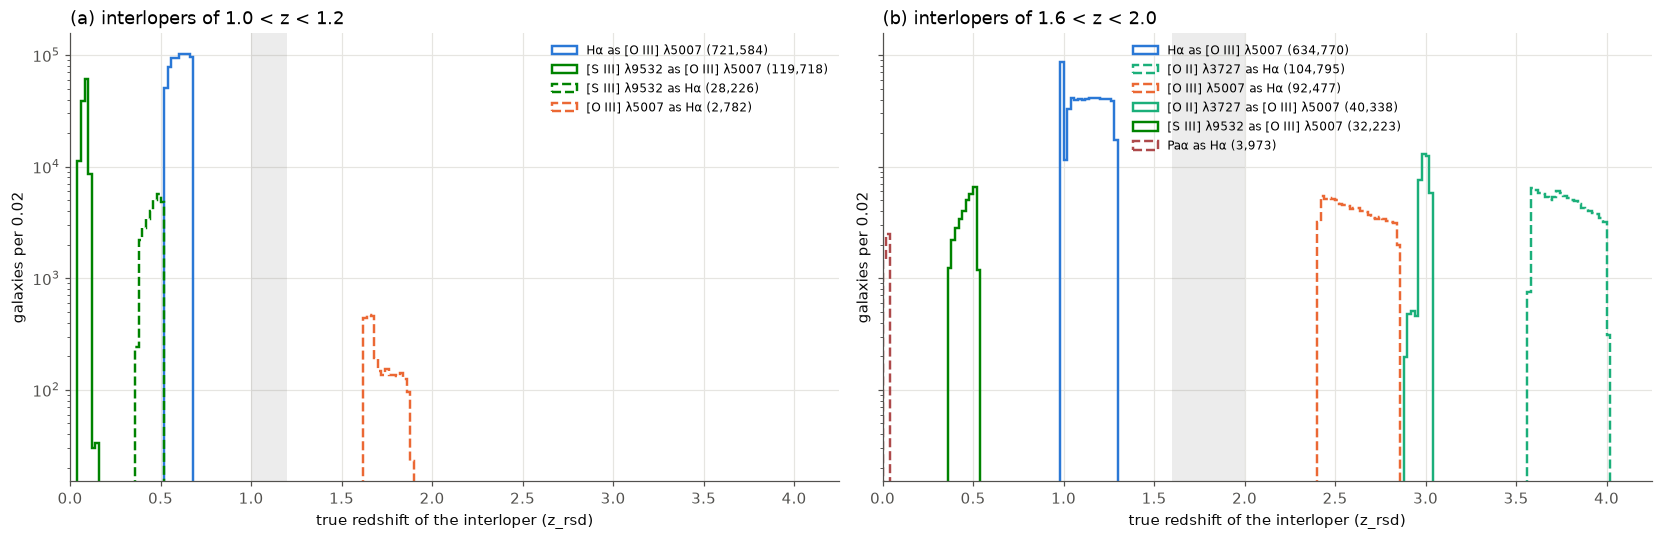

In [8]:
def show_origins(cat, name, ax, z_range, min_count=1000):
    """The true redshift of each kind of interloper with at least min_count galaxies; z_range shaded."""
    comp = cat.components()
    styles = {}
    bins = np.arange(0.0, 4.25, 0.02)
    for which, n in sorted(comp.items(), key=lambda kv: -kv[1]):
        if "_as_" not in which or n < min_count:
            continue
        true, taken = which.split("_as_")
        ls = styles.setdefault(taken, ("-", "--", ":")[len(styles) % 3])
        ax.hist(np.asarray(cat.subset(which)["redshift_rsd"]), bins, histtype="step", color=feature_color(true), ls=ls,
                lw=1.6, label=f"{feature_label(true)} as {feature_label(taken)} ({n:,})")
    ax.axvspan(*z_range, color="0.5", alpha=0.15, lw=0)
    ax.set_yscale("log")
    ax.set_xlim(0, 4.25)
    ax.set_xlabel("true redshift of the interloper (z_rsd)")
    ax.set_ylabel("galaxies per 0.02")
    ax.set_title(name, loc="left")
    ax.legend(fontsize=8)


fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), constrained_layout=True, sharey=True)
show_origins(cat, "(a) interlopers of 1.0 < z < 1.2", axes[0], proposal.z_range)
show_origins(cat_2, "(b) interlopers of 1.6 < z < 2.0", axes[1], proposal_2.z_range)
plt.show()

Every interloper comes from outside the range, from where its line falls where Hα or [O III] would be inside it: Hα of
z ≈ 0.6 and z ≈ 1.1 taken for [O III], [S III] λ9532 below z = 0.6, [O III] of z ≈ 1.75 and z ≈ 2.6, [O II] of z ≈ 3.0
and z ≈ 3.8, and Paα of z < 0.03.

## Other lines to take the single lines for

`proposal.worst_case(taken_for)` gives the worst case for any list of lines, and
`make_catalog({"type": "worst_case", "taken_for": [...]}, out_dir)` makes it. With Hα alone, the single lines of other
redshifts can only pass for Hα, as in a catalog of Hα emitters; with [O III] alone, only for [O III].
`worst_case_lines(min_count=100)` drops the 0.1 % share: every line that is the single line of at least 100 galaxies
inside the range.

In [9]:
for p in (proposal, proposal_2):
    lo, hi = p.z_range
    print(f"{lo} < z < {hi}: lines single inside the range {p.worst_case_lines()}; "
          f"with at least 100 galaxies, whatever their share: {p.worst_case_lines(min_count=100)}")
    for taken_for in (p.worst_case_lines(), ["Ha"], ["OIII_5007"]):
        w = p.worst_case(taken_for)
        print(f"  taken for {' and '.join(taken_for):<16s}{w['n_interlopers']:>10,} interlopers, "
              f"{100 * w['share']:5.2f} % of {w['n_catalog']:,}")

1.0 < z < 1.2: lines single inside the range ['Ha', 'OIII_5007']; with at least 100 galaxies, whatever their share: ['Ha', 'OIII_5007']
  taken for Ha and OIII_5007   872,310 interlopers,  6.19 % of 14,096,887
  taken for Ha                  31,008 interlopers,  0.23 % of 13,255,585
  taken for OIII_5007          841,302 interlopers,  5.98 % of 14,065,879
1.6 < z < 2.0: lines single inside the range ['Ha', 'OIII_5007']; with at least 100 galaxies, whatever their share: ['Ha', 'OIII_5007']
  taken for Ha and OIII_5007   908,576 interlopers,  9.02 % of 10,068,845
  taken for Ha                 201,245 interlopers,  2.15 % of 9,361,514
  taken for OIII_5007          707,331 interlopers,  7.17 % of 9,867,600


* **Hα alone** gives 0.23 % at 1.0–1.2 and 2.15 % at 1.6–2.0: the single Hα lines of z ≈ 0.6 and z ≈ 1.1, which pass
  for [O III], are then never interlopers.
* **[O III] alone** gives 5.98 % and 7.17 %: most of the worst case comes from single lines taken for [O III].
* **Without the share cut** (`min_count=100`) the lines are the same in both ranges at these thresholds. The cut matters
  where a line is the single line of a handful of galaxies, e.g. Hβ and [O II] at 1.6–2.0 with a single tier (207 and
  136 of 5.5 M single-line galaxies, notebook 04): taking the single Hα lines of z ≈ 1 for Hβ would make them most of
  the catalog.

## The files

As in notebook 01: `<name>.hdf5`, `<name>_summary.json` and `<name>_proposal.npz` in each directory. The summary keeps
the worst case, expected and made (`worst_case`), and the identification (`settings["confusion"]`, with the lines it
took the single lines for), so the catalog can be made again from it.

In [10]:
for d in ("all_z1p0_1p2_worst_case", "all_z1p6_2p0_worst_case"):
    print(d + ":", ", ".join(sorted(p.name for p in (OUT / d).iterdir() if p.is_file())))
summary = json.loads((OUT / "all_z1p0_1p2_worst_case" / "all_z1p0_1p2_summary.json").read_text())
print("identification:", summary["settings"]["confusion"])
w = summary["worst_case"]
print(f"expected {w['n_interlopers']:,} interlopers in {w['n_catalog']:,}; made {w['made']['n_interlopers']:,} in "
      f"{w['made']['n_catalog']:,}")

all_z1p0_1p2_worst_case: all_z1p0_1p2.hdf5, all_z1p0_1p2_proposal.npz, all_z1p0_1p2_summary.json
all_z1p6_2p0_worst_case: all_z1p6_2p0.hdf5, all_z1p6_2p0_proposal.npz, all_z1p6_2p0_summary.json
identification: {'type': 'worst_case', 'z_range': [1.0, 1.2], 'taken_for': ['Ha', 'OIII_5007']}
expected 872,310 interlopers in 14,096,887; made 872,310 in 14,096,887


## Summary

* **`proposal.make_catalog("worst_case", out_dir)`** makes the catalog in which every single line is an interloper:
  taken for a line that single-line galaxies inside the range show (`proposal.worst_case_lines()`), for one that puts
  it inside the range wherever there is one. **`proposal.worst_case_summary()`** gives it in advance from the counts,
  and the catalog matches it exactly.
* With flux limits of 1.5 / 0.6 × 10⁻¹⁶ and the rescaled oxygen lines: **6.19 % of interlopers at 1.0–1.2**, 5.1 % of
  them Hα of z ≈ 0.6 taken for [O III], and **9.02 % at 1.6–2.0**, 6.3 % Hα of z ≈ 1.1 taken for [O III] and 19 % above
  z = 1.94.
* **No single line of either range stays inside it with a wrong redshift**: Hα and [O III] are too far apart, and the
  lines close enough to do it ([S III] λ6312, [O III] λ4959, Hβ) are never single there.
* `proposal.misidentifications()` lists every way a single line can get a redshift inside the range;
  `{"type": "worst_case", "taken_for": [...]}` takes the single lines for other lines.
* The notebook ran in 2.4 minutes on a CPU node.